dt = 0.005, C + 2D = 0.50
dt = 0.01, C + 2D = 1.00
dt = 0.015, C + 2D = 1.50


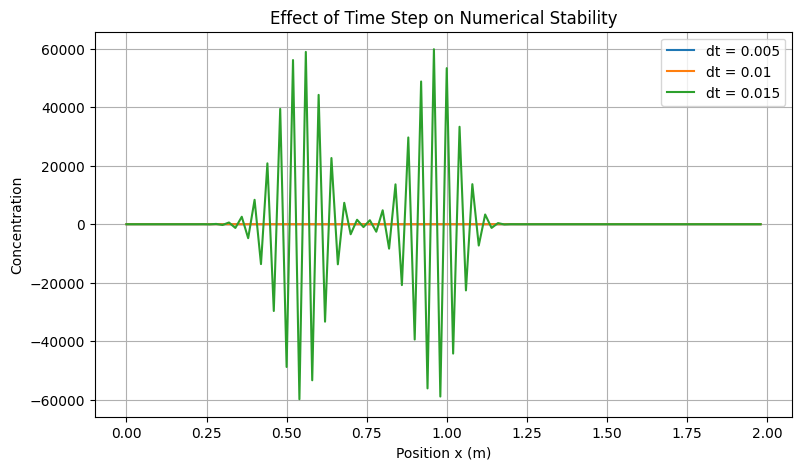

In [7]:
# 1D Convection–Diffusion Equation

import numpy as np
import matplotlib.pyplot as plt

# 1.Computation Domain

L=2.0
nx=100
dx=L/nx
x=np.arange(nx)*dx

# 2.Physical Parameters

u=1.0 # Velocity
nu=0.01 # Diffusion coefficient 

# 3.Initial Concentration

def initial_condition():
    phi=np.zeros(nx)
    phi[(x>=0.4)&(x<=0.8)]=1.0
    return phi
# 4.Numerical Solver

def solve(dt,T):
    phi=initial_condition()
    
    nt=round(T/dt)
    
    C=u*dt/dx
    D=nu*dt/dx**2
    
    for n in range(nt):
        old=phi.copy()
        
        convection=-C*(old-np.roll(old,1))
        
        diffusion=D*(np.roll(old,-1)-2*old+np.roll(old,1))
        
        phi=old+convection+diffusion
        
    return phi, C, D

# 5. Compare time steps

T=0.3
plt.figure(figsize=(9, 5))

for dt in [0.005, 0.010, 0.015]:
    phi, C, D = solve(dt, T)

    print(f"dt = {dt}, C + 2D = {C + 2*D:.2f}")

    plt.plot(x, phi, label=f"dt = {dt}")

plt.xlabel("Position x (m)")
plt.ylabel("Concentration")
plt.title("Effect of Time Step on Numerical Stability")
plt.legend()
plt.grid(True)
plt.show()


dt=0.001, steps=500, max speed=1.0000, final max CFL=0.0200, final stability indicator=0.1800, final RMS divergence=1.035e-01
dt=0.003, steps=200, max speed=1.0000, final max CFL=0.0500, final stability indicator=0.4500, final RMS divergence=1.578e-01
dt=0.005, steps=100, max speed=1.0000, final max CFL=0.1000, final stability indicator=0.9000, final RMS divergence=2.051e-01


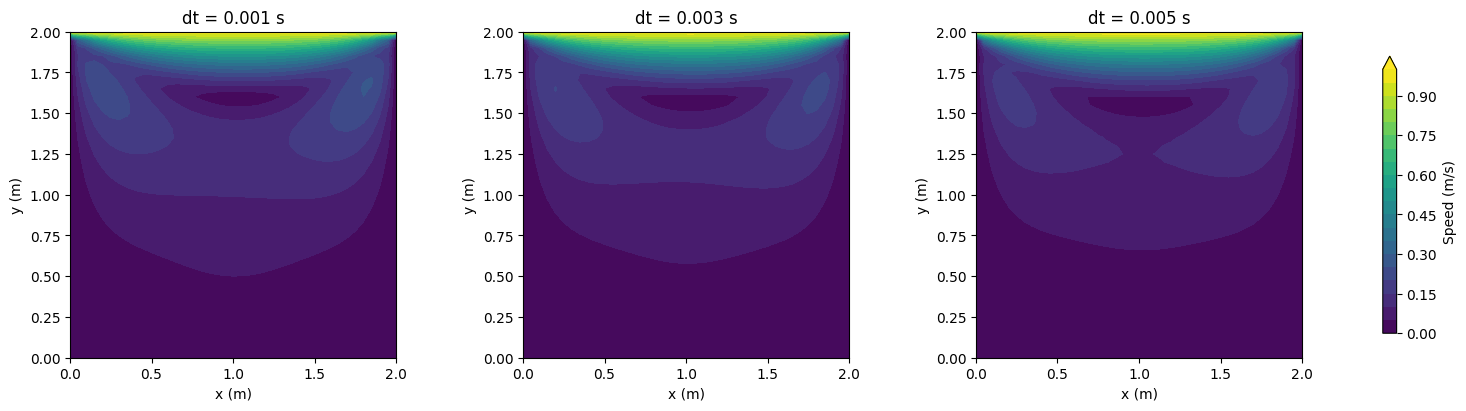

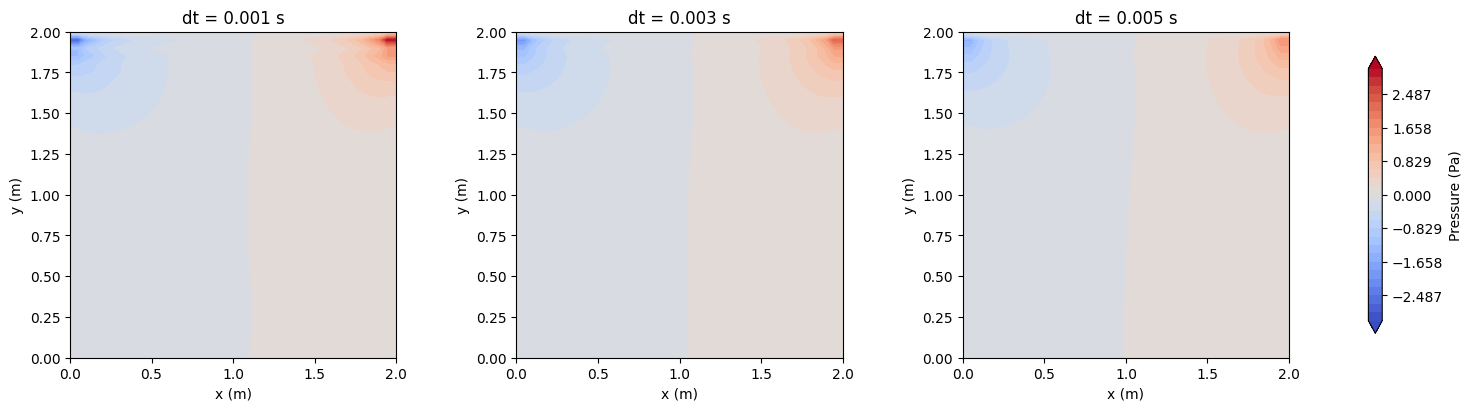

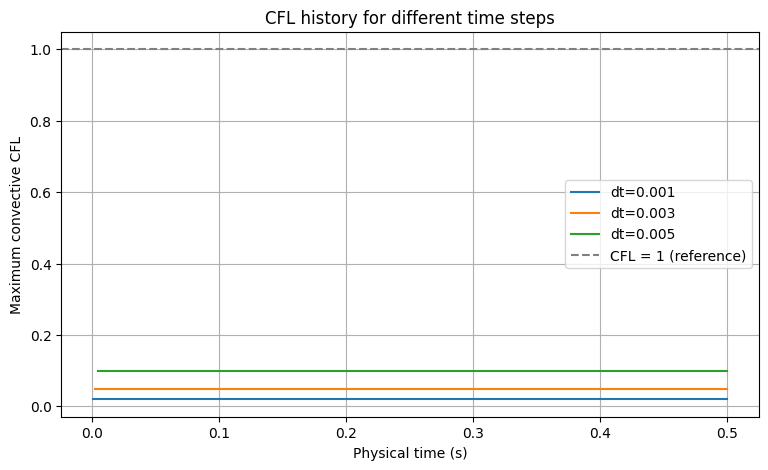

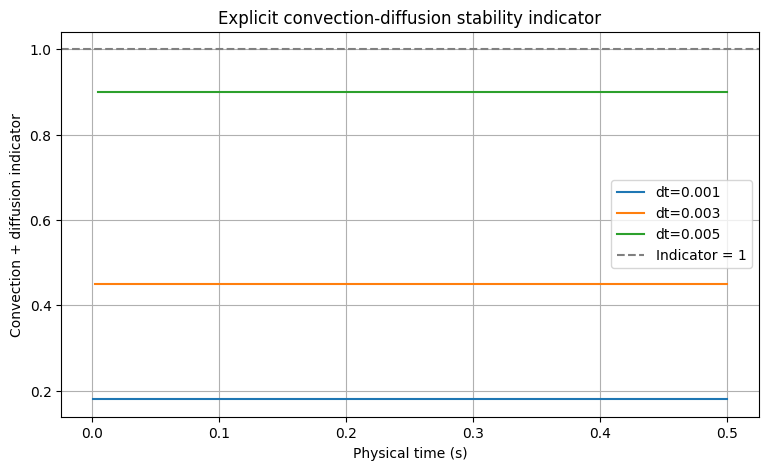

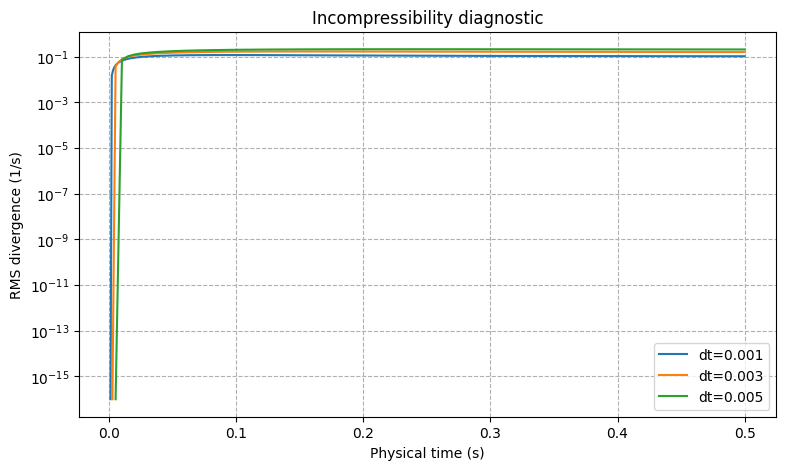

In [21]:
import numpy as np
import matplotlib.pyplot as plt

1.# Create the domain and the physical parameters
Lx=Ly=2.0
nx=ny=41
dx=Lx/(nx-1)
dy=Ly/(ny-1)
x=np.linspace(0,Lx,nx)
y=np.linspace(0,Ly,ny)
X,Y=np.meshgrid(x,y)

rho=1.0
nu=0.1
lid_velocity=1.0
nit=50
T=0.5
dt_values=[0.001,0.0025,0.005]

# 3.Construct the pressure source term

def build_up_b(b,rho,dt,u,v,dx,dy):
    dudx=(u[1:-1,2:]-u[1:-1,:-2])/(2*dx)
    dudy=(u[2:,1:-1]-u[:-2,1:-1])/(2*dy)
    dvdx=(v[1:-1,2:]-v[1:-1,:-2])/(2*dx)
    dvdy=(v[2:,1:-1]-v[:-2,1:-1])/(2*dy)
    
    divergence=dudx+dvdy
    
    b[1:-1,1:-1]=rho*(divergence/dt-dudx**2-2*dudy*dvdx-dvdy**2)
    return b

# 4.Solve the pressure Poisson equation

def pressure_poisson(p,dx,dy,b):
    
    for _ in range(nit):
        pn=p.copy()
        p_right=pn[1:-1,2:]
        p_left=pn[1:-1,:-2]
        p_up=pn[2:,1:-1]
        p_down=pn[:-2,1:-1]
        
        term_x=(p_right+p_left)*dy**2
        term_y=(p_up+p_down)*dx**2
        
        denominator=2*(dx**2+dy**2)
        
        source=(dx**2*dy**2/denominator)*b[1:-1,1:-1]
        
        p[1:-1,1:-1]=(term_x+term_y)/denominator-source
        
        p[:, -1] = p[:, -2]  # Right
        p[:, 0] = p[:, 1]    # Left
        p[0, :] = p[1, :]    # Bottom
        p[-1, :] = 0         # Top

    return p

def solve(dt):
    
    u=np.zeros((ny,nx)) #velocity in x-direction
    v=np.zeros((ny,nx)) #velocity in y-direction
    p=np.zeros((ny,nx)) #pressure field
    b=np.zeros((ny,nx)) #Right hand side of pressure equation
    nt=round(T/dt)
    times,cfl_history,stability_history,divergence_history=[],[],[],[]
    
    for n in range(nt):
    
        un=u.copy()
        vn=v.copy()
                
        #build the pressure source term
        b=build_up_b(b,rho,dt,un,vn,dx,dy)

        #Calculate pressure
        p=pressure_poisson(p,dx,dy,b)

        u_center=un[1:-1,1:-1]
        v_center=vn[1:-1,1:-1]

        #Velocity gradients
        dudx=np.where(u_center>=0,
                     (u_center-un[1:-1,:-2])/dx,
                     (un[1:-1,2:]-u_center)/dx)

        dudy=np.where(v_center>=0,
                     (u_center-un[:-2,1:-1])/dy,
                     (un[2:,1:-1]-u_center)/dy)

        dvdx=np.where(u_center>=0,
                     (v_center-vn[1:-1,:-2])/dx,
                     (vn[1:-1,2:]-v_center)/dx)

        dvdy=np.where(v_center>=0,
                     (v_center-vn[:-2,1:-1])/dy,
                     (vn[2:,1:-1]-v_center)/dy)

        #Pressure gradients
        dpdx=(p[1:-1,2:]-p[1:-1,:-2])/(2*dx)
        dpdy=(p[2:,1:-1]-p[:-2,1:-1])/(2*dy)

        d2udx2=(un[1:-1,2:]-2*u_center+un[1:-1,:-2])/dx**2
        d2udy2=(un[2:,1:-1]-2*u_center+un[:-2,1:-1])/dy**2
        d2vdx2=(vn[1:-1,2:]-2*v_center+vn[1:-1,:-2])/dx**2
        d2vdy2=(vn[2:,1:-1]-2*v_center+vn[:-2,1:-1])/dy**2

        # Convection terms
        convection_u=-(u_center*dudx+v_center*dudy)
        convection_v=-(u_center*dvdx+v_center*dvdy)

        # Pressure gradient terms
        pressure_u=-dpdx/rho
        pressure_v=-dpdy/rho

        # Viscous diffusion terms
        diffusion_u=nu*(d2udx2+d2udy2)
        diffusion_v=nu*(d2vdx2+d2vdy2)

        # Update velocity components
        u[1:-1,1:-1]=un[1:-1,1:-1]+dt*(convection_u+pressure_u+diffusion_u)
        v[1:-1,1:-1]=vn[1:-1,1:-1]+dt*(convection_v+pressure_v+diffusion_v)

        # Velocity boundary conditions:
        u[0,:]=0.0
        u[:,0]=0.0
        u[:,-1]=0.0
        u[-1,:]=1

        v[0,:]=0.0
        v[:,0]=0.0
        v[:,-1]=0.0
        v[-1,:]=0.0

        # Calculate CFL
        local_cfl=np.abs(u) * dt/dx + np.abs(v) * dt/dy
        max_cfl=float(np.max(local_cfl))
        diffusion_contribution = 2 * nu * dt * (1 / dx**2 +1 / dy**2)
        max_stability=max_cfl + diffusion_contribution
        div = ((u[1:-1,2:] - u[1:-1,:-2])/(2*dx) + (v[2:,1:-1] - v[:-2,1:-1])/(2*dy))
        div_rms=float(np.sqrt(np.mean(div**2)))
        times.append((n+1)*dt)
        cfl_history.append(max_cfl)
        stability_history.append(max_stability)
        divergence_history.append(div_rms)

        if not (np.isfinite(u).all() and np.isfinite(v).all() and np.isfinite(p).all()):
            print(f'WARNING: dt={dt} produced non-finite values at step {n+1}')
            break
        if max_stability > 1 and n==0:
            print(f'WARNING: dt={dt}: initial explicit convection-diffusion indicator exceeds 1')
    
    return {'dt':dt, 'u':u, 'v':v, 'p':p,
            'times':np.array(times),'cfl':np.array(cfl_history),
            'stability':np.array(stability_history),
            'divergence':np.array(divergence_history)}

results=[solve(dt) for dt in dt_values]
for r in results:
    speed = np.hypot(r['u'],r['v'])
    print(f"dt={r['dt']:.3f}, steps={len(r['times'])}, "
          f"max speed={np.max(speed):.4f}, "
          f"final max CFL={r['cfl'][-1]:.4f}, "
          f"final stability indicator={r['stability'][-1]:.4f}, "
          f"final RMS divergence={r['divergence'][-1]:.3e}")

# Plot 1: speed contour comparison
fig, axes = plt.subplots(1, len(results), figsize=(15, 4), constrained_layout=True)
max_speed = max(np.max(np.hypot(r['u'], r['v'])) for r in results)
levels = np.linspace(0, max(1.0, max_speed), 21)
for ax, r in zip(axes, results):
    speed = np.hypot(r['u'], r['v'])
    cf = ax.contourf(X, Y, speed, levels=levels, cmap='viridis', extend='max')
    ax.set_title(f"dt = {r['dt']:.3f} s")
    ax.set_xlabel('x (m)')
    ax.set_ylabel('y (m)')
    ax.set_aspect('equal')
fig.colorbar(cf, ax=axes, label='Speed (m/s)', shrink=0.85)
plt.show()

# Plot 2: pressure contour comparison
fig, axes = plt.subplots(1, len(results), figsize=(15, 4), constrained_layout=True)
abs_p = max(np.max(np.abs(r['p'])) for r in results)
levels = np.linspace(-max(abs_p, 1e-6), max(abs_p, 1e-6), 31)
for ax, r in zip(axes, results):
    cf = ax.contourf(X, Y, r['p'], levels=levels, cmap='coolwarm', extend='both')
    ax.set_title(f"dt = {r['dt']:.3f} s")
    ax.set_xlabel('x (m)')
    ax.set_ylabel('y (m)')
    ax.set_aspect('equal')
fig.colorbar(cf, ax=axes, label='Pressure (Pa)', shrink=0.85)
plt.show()

# Plot 3: CFL history
plt.figure(figsize=(9, 5))
for r in results:
    plt.plot(r['times'], r['cfl'], label=f"dt={r['dt']:.3f}")
plt.axhline(1.0, color='gray', linestyle='--', label='CFL = 1 (reference)')
plt.xlabel('Physical time (s)')
plt.ylabel('Maximum convective CFL')
plt.title('CFL history for different time steps')
plt.grid(True)
plt.legend()
plt.show()

# Plot 4: combined explicit stability indicator
plt.figure(figsize=(9, 5))
for r in results:
    plt.plot(r['times'], r['stability'], label=f"dt={r['dt']:.3f}")
plt.axhline(1.0, color='gray', linestyle='--', label='Indicator = 1')
plt.xlabel('Physical time (s)')
plt.ylabel('Convection + diffusion indicator')
plt.title('Explicit convection-diffusion stability indicator')
plt.grid(True)
plt.legend()
plt.show()

# Plot 5: divergence diagnostic
plt.figure(figsize=(9, 5))
for r in results:
    plt.semilogy(r['times'], np.maximum(r['divergence'], 1e-16), label=f"dt={r['dt']:.3f}")
plt.xlabel('Physical time (s)')
plt.ylabel('RMS divergence (1/s)')
plt.title('Incompressibility diagnostic')
plt.grid(True, which="both", ls="--") 
plt.legend()
plt.show()
